Flusso di Poiseuille con sviluppo MLP

In [ ]:
# @markdown Importazione delle librerie
import numpy as np

import torch
import torch.nn as nn
from torch.optim import Adam # l'ottimizzatore

import matplotlib.pyplot as plt

import time
from tqdm.auto import tqdm  # barra di avanzamento per le epoche

SEED = 1234
print(f"SEED={SEED}")
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device in uso: {device}")
torch.set_float32_matmul_precision('high') # meno cifre nelle operazioni -> tempi più brevi

SEED=1234
Device in uso: cuda


In [ ]:
# @markdown DEFINIZIONE DELLE VARIABILI ("mostra codice" per cambiare i valori)

# DOMINIO FISICO (tubo)
Lx = 7.
Ly = 1.

# COLLOCATION POINTS PER LE CONDIZIONI AL CONTRONO (DIRICHLET)
N_b = 1000

# IN CASO DI COLLOCATION POINTS FISSATI (modificare il ciclo di traning con i tensori già predisposti invece che con i tensori dati dalla funzione di batching)
N_f = 10000 # collocation points

# IN CASO DI COLLOCATION POINTS NON FISSATI (mini batching)
N_f_batch = 1000

# A SECONDA SE SI FACCIA MINI-BATCHING O MENO BISOGNA CERCARE LE FUNZIONE loss_pde, e commentare la versione non utile, lasciando solo quella utile.

# PARAMETRI FLUIDODINAMICI E VARIABILI AUSILIARIE
# parametri fisici ademensionali
rho = 1.0        # densità
mu  = 0.01       # viscosità dinamica
nu  = mu / rho   # viscosità cinematica

# velocità = 1 sulle x, ed = 0 sulle y
U_inlet = 2/3    # componente velocità sulle x imposta in ingresso, al massimo (profilo parabolico della velocità), si assume velocità nulla ai borrdi per il no-slip
V_inlet = 0.0    # componente v imposta in ingresso (flusso puramente assiale)

# velocità caratteristica e lunghezza caratteristica, per il numero di Reynolds
U_ref = 1      # velocità caratteristica (di inlet)
L_ref = Ly       # lunghezza caratteristica (del canale)

# CONDIZIONI DI DIRICHLET

# # caratteristiche dell'uscita
# U_outlet = 1.0
# V_outlet = 0.0
# condizioni di no-slip alle pareti
U_wall = 0.0
V_wall = 0.0

# COEFFICIENTI DEI TERMINI DELLA LOSS
lambda_continuity = 1.0
lambda_momentum_x = 1.0
lambda_momentum_y = 1.0
lambda_inlet = 1.0
lambda_outlet = 1.0
lambda_walls = 1.0
# per ricavarli si può fare un primo allenamento imponendoli tutti uguali ad 1 e leggere i risultati della penultima cella per correggerli per i prossimi cicli di training

# PARAMETRI DEL MODELLO
in_dim = 2 # numero di grandezze fisiche in entrata (x ed y, senza tempo)
out_dim = 3 # numero di grandezze fisiche in uscita (vx, vy e pressione)
hidden_dim = 128
n_layers = 3               # numero di stratri MFN (modified fuorier network) se impostato a 0 o 1 sarà dato da (FuorierEmbed -> Linear U x Linear V x Linear input -> Hidden layers (non ci sono, non si usano ne U, ne V) -> Linear output)

# PARAMETRI DELL'OTTIMIZZATORE E DI LEARNING
lri = 1e-2            # learning rate iniziale
gamma = 0.1           # fattore di moltiplicazione del learnin rate
N_EPOCHS = 36000      # autoesplicativo
step_size = int(N_EPOCHS/3)      # numero di epoche che deve passare prima che lr venga moltiplicato per il fattore gamma
# ottimizzatore adam con


In [ ]:
# @markdown Definizione dei punti di collocazione

# punti di collocazione
def sample_interior(n):
    x = np.random.uniform(0, Lx, (n, 1))
    y = np.random.uniform(0, Ly, (n, 1))
    return x, y

x_f, y_f = sample_interior(N_f)

# punti di ingresso (bordo sinistro, x = 0)
def sample_inlet(n):
    x = np.zeros((n, 1))
    y = np.random.uniform(0, Ly, (n, 1))
    return x, y

x_in, y_in = sample_inlet(N_b)

# punti di uscita (bordo destro, x = Lx)
def sample_outlet(n):
    x = np.full((n, 1), Lx)
    y = np.random.uniform(0, Ly, (n, 1))
    return x, y

x_out, y_out = sample_outlet(N_b)

# punti sulle pareti (y = 0, y = Ly)
# no-slip e condizioni al contorno addizionali
def sample_walls(n):
    x_w = np.random.uniform(0, Lx, (n, 1))
    y_bottom = np.zeros((n, 1))
    y_top    = np.full((n, 1), Ly)
    return x_w, y_bottom, y_top

x_w, y_bottom, y_top = sample_walls(N_b)

#Conversione in tensori torch

# per i prossimi numpy -> tensori si tratta di punti interni
# dobbiamo poter minimzzare la loss, ci servono le derivate
X_f = torch.tensor(x_f, dtype=torch.float32, requires_grad=True).to(device)
Y_f = torch.tensor(y_f, dtype=torch.float32, requires_grad=True).to(device)

# per i prossimi punti si tratta di punti ausiliari dove imporre condizioni
# al contorno, che non cambiano e che non riguardano navier-stokes, non serve
# poter calcolare il gradiente
X_in = torch.tensor(x_in, dtype=torch.float32, requires_grad=False).to(device)
Y_in = torch.tensor(y_in, dtype=torch.float32, requires_grad=False).to(device)

X_out = torch.tensor(x_out, dtype=torch.float32, requires_grad=True).to(device)
Y_out = torch.tensor(y_out, dtype=torch.float32, requires_grad=True).to(device)

X_w = torch.tensor(x_w, dtype=torch.float32, requires_grad=False).to(device)
Y_bottom = torch.tensor(y_bottom, dtype=torch.float32, requires_grad=False).to(device)
Y_top = torch.tensor(y_top, dtype=torch.float32, requires_grad=False).to(device)

print(f"Punti interni:  {X_f.shape[0]}")
print(f"Punti inlet:    {X_in.shape[0]}")
print(f"Punti outlet:   {X_out.shape[0]}")
print(f"Punti pareti:   {X_w.shape[0]} (top+bottom)")

Punti interni:  10000
Punti inlet:    1000
Punti outlet:   1000
Punti pareti:   1000 (top+bottom)


In [ ]:
# @markdown Calcolo dei parametri fluidodinamici

# numero di Reynolds
Re = U_ref * L_ref / nu
print(f"Numero di Reynolds: Re = {Re:.2f}")

# coefficiente di viscosità per le eq. adimensionali
inv_Re = 1.0 / Re

print(f"rho = {rho}, mu = {mu}, nu = {nu:.5f}")
print(f"1/Re = {inv_Re:.5f}")

Numero di Reynolds: Re = 100.00
rho = 1.0, mu = 0.01, nu = 0.01000
1/Re = 0.01000


In [ ]:
# @markdown Implementazione di N-S 2D, condizioni al bordo e delle Loss in generale ("mostra codice per modificare le loss")

# funzione di passaggio, prende il modello
# restituisce u, v (velocità sulle x, velocità sulle y) e p (pressione)
# per un batch di punti (x, y)

def net_uvp(model, x, y):   # non dipentente dal tempo (per problemi stazionari fa risparmiare molto tempo di calcolo)
    inputs = torch.cat([x, y], dim=1)
    out = model(inputs)
    return out[:, 0:1], out[:, 1:2], out[:, 2:3]


# residuo delle equazioni di navier-stokes 2D, da usare poi nella loss
# incomprimibili, adimensionali, nei punti interni, costante nel tempo
def navier_stokes_residual(model, x, y, inv_Re):
    u, v, p = net_uvp(model, x, y)
    ones_u, ones_v, ones_p = torch.ones_like(u), torch.ones_like(v), torch.ones_like(p)

    u_x, u_y = torch.autograd.grad(u, [x, y], grad_outputs=ones_u, create_graph=True)
    v_x, v_y = torch.autograd.grad(v, [x, y], grad_outputs=ones_v, create_graph=True)
    p_x, p_y = torch.autograd.grad(p, [x, y], grad_outputs=ones_p, create_graph=True)

    u_xx = torch.autograd.grad(u_x, x, grad_outputs=ones_u, create_graph=True)[0]
    u_yy = torch.autograd.grad(u_y, y, grad_outputs=ones_u, create_graph=True)[0]
    v_xx = torch.autograd.grad(v_x, x, grad_outputs=ones_v, create_graph=True)[0]
    v_yy = torch.autograd.grad(v_y, y, grad_outputs=ones_v, create_graph=True)[0]

    continuity = u_x + v_y
    momentum_x = u * u_x + v * u_y + p_x - inv_Re * (u_xx + u_yy)  # niente u_t
    momentum_y = u * v_x + v * v_y + p_y - inv_Re * (v_xx + v_yy)  # niente v_t

    return continuity, momentum_x, momentum_y

# versione per poseuille, senza tempo, utile per mini-batching
def loss_pde(model, x, y):
    continuity, momentum_x, momentum_y = navier_stokes_residual(model, x, y, inv_Re)
    mse_continuity = torch.mean(continuity**2)
    mse_momentum_x = torch.mean(momentum_x**2)
    mse_momentum_y = torch.mean(momentum_y**2)
    return mse_continuity, mse_momentum_x, mse_momentum_y


def poiseuille_profile(y, U_inlet, Ly):
    """Profilo parabolico: 0 alle pareti, U_inlet al centro."""
    return 4 * U_inlet * y * (Ly - y) / (Ly**2)

# lo implementiamo in una funzione sola per risparmiare sulle chiamate, senza tempo
def loss_boundaries(model):
    # concatena TUTTI i punti di bordo in un unico batch
    x_all = torch.cat([X_in, X_out, X_w, X_w], dim=0)
    y_all = torch.cat([Y_in, Y_out, Y_bottom, Y_top], dim=0)

    u_all, v_all, p_all = net_uvp(model, x_all, y_all)   # UN SOLO forward pass

    n = N_b
    u_in, v_in       = u_all[0:n],     v_all[0:n]
    u_out, v_out, p_out   = u_all[n:2*n],   v_all[n:2*n], p_all[n:2*n]
    u_bot, v_bot     = u_all[2*n:3*n], v_all[2*n:3*n]
    u_top, v_top     = u_all[3*n:4*n], v_all[3*n:4*n]

    # ones_u = torch.ones_like(u_out)
    # ones_v = torch.ones_like(v_out)
    # u_x = torch.autograd.grad(u_out, X_out, grad_outputs=ones_u, create_graph=True)[0]
    # v_x = torch.autograd.grad(v_out, X_out, grad_outputs=ones_v, create_graph=True)[0]

    # target_u_in = poiseuille_profile(Y_in, U_inlet, Ly) #in caso si voglia fare il poiseuille sviluppato
    target_u_in = torch.full_like(u_in, U_inlet)
    l_in   = torch.mean((u_in - target_u_in)**2) + torch.mean(v_in**2)
    # implementiamo condizioni al contorno sul bordo destro del tubo sul campo della velocità
    l_out  = torch.mean(p_out**2) #+ torch.mean(u_x**2) + torch.mean(v_x**2)
    l_wall = torch.mean(u_bot**2) + torch.mean(v_bot**2) + torch.mean(u_top**2) + torch.mean(v_top**2)

    return l_in, l_out, l_wall


# loss totale = comb. lineare delle loss precedenti

# ridefiniamo la loss totale in modo che si adegui al mini-batching e sia stazionaria
def total_loss(model, x_f, y_f):
    mse_continuity, mse_momentum_x, mse_momentum_y = loss_pde(model, x_f, y_f)
    l_in, l_out, l_wall = loss_boundaries(model)

    loss = (lambda_continuity * mse_continuity +
            lambda_momentum_x * mse_momentum_x +
            lambda_momentum_y * mse_momentum_y +
            lambda_inlet      * l_in +
            lambda_outlet     * l_out +
            lambda_walls      * l_wall)

    components = {
        "continuity": mse_continuity.detach(),
        "momentum_x": mse_momentum_x.detach(),
        "momentum_y": mse_momentum_y.detach(),
        "inlet": l_in.detach(),
        "outlet": l_out.detach(),
        "walls": l_wall.detach(),
        "total": loss.detach()
    }
    return loss, components

In [ ]:
# @markdown Definizione della rete neurale (Multi-Layer Perceptron)

# Definizione della rete neurale (MLP con attivazione tanh)

class MLP(nn.Module):
    """
    Multi-Layer Perceptron per PINN.
    Input: (x, y, t) -> Output: (u, v, p)
    """
    def __init__(self, in_dim=3, out_dim=3, hidden_dim=256, n_layers=6):
        super().__init__()

        layers = []

        # Layer di ingresso
        layers.append(nn.Linear(in_dim, hidden_dim))
        layers.append(nn.Tanh())

        # Layer nascosti successivi
        for _ in range(n_layers - 1):
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(nn.Tanh())

        self.hidden_layers = nn.Sequential(*layers)

        # Layer di output
        self.output_layer = nn.Linear(hidden_dim, out_dim)

    def forward(self, x):
        H = self.hidden_layers(x)
        out = self.output_layer(H)
        return out


# Creazione del modello
model = MLP(
    in_dim=in_dim,
    out_dim=out_dim,
    hidden_dim=hidden_dim,
    n_layers=n_layers
).to(device)

# Conteggio dei parametri allenabili
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Numero totale di parametri: {n_params:,}")
print(model)

Numero totale di parametri: 33,795
MLP(
  (hidden_layers): Sequential(
    (0): Linear(in_features=2, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): Tanh()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): Tanh()
  )
  (output_layer): Linear(in_features=128, out_features=3, bias=True)
)


In [ ]:
# @markdown Ottimizzatore ADAM (per usare SGD mostrare il codice della cella precedente)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=lri,
    betas=(0.9, 0.999),
    eps=1e-8,
    weight_decay=0.0
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=step_size,
    gamma=gamma
)

print(f"Ottimizzatore Adam")

Ottimizzatore Adam


In [ ]:
# @markdown Preparazione del mini-batching

# ci prepariamo al minibatching con una funzione che trova dei punti randomici all'interno del canale
# vengono sempre valutate le loss su tutti i punti di frontiera del dominio

# questa cella si può commentare in caso si faccia traning a collocation points fissati

def sample_interior_batch(n):
    """Campiona n punti casuali nel dominio (x,y,(senza)t), pronti per autograd."""
    x = torch.rand(n, 1, device=device) * Lx
    y = torch.rand(n, 1, device=device) * Ly
    x.requires_grad_(True)
    y.requires_grad_(True)
    return x, y

In [ ]:
# @markdown TRAINING LOOP ("Mostra codice" per modificare il calcolo della loss e renderlo sui punti desiderati)

component_names = ["total", "continuity", "momentum_x", "momentum_y", "inlet", "outlet", "walls"]

history_gpu = torch.zeros(N_EPOCHS, len(component_names), device=device)

model.train()
start_time = time.time()

pbar = tqdm(range(N_EPOCHS), desc="Training PINN")
for epoch in pbar:
    optimizer.zero_grad()

    x_batch, y_batch = sample_interior_batch(N_f_batch)

    # usare al posto di x_batch, y_batch, X_f e Y_f se si vuole collocation point fissati!

    # loss, components = total_loss(model, X_F, Y_f)
    loss, components = total_loss(model, x_batch, y_batch)

    loss.backward()
    optimizer.step()

    with torch.no_grad():
        for i, key in enumerate(component_names):
            history_gpu[epoch, i] = components[key]

    if epoch % 100 == 0 or epoch == N_EPOCHS - 1:
        pbar.set_postfix({
            "loss": f"{components['total'].item():.4e}",
            "cont": f"{components['continuity'].item():.2e}",
            "mom_x": f"{components['momentum_x'].item():.2e}",
            "mom_y": f"{components['momentum_y'].item():.2e}",
            "in": f"{components['inlet'].item():.2e}",
            "out (p)": f"{components['outlet'].item():.2e}",
            "wall": f"{components['walls'].item():.2e}",
        })

    if epoch % 2000 == 0:
        elapsed = time.time() - start_time
        print(f"[Epoch {epoch:5d}/{N_EPOCHS}] "
              f"loss = {components['total'].item():.6e}  "
              f"(elapsed: {elapsed/60:.1f} min)")

    scheduler.step()

total_time = time.time() - start_time
print(f"\nTraining completato in {total_time/60:.1f} minuti ({total_time/3600:.2f} ore)")

# potremmo mettere le due righe di seguito qui, ma per poter interrompere il training ed avere una rete "funzionante", meglio metterle nelle celle del plot

Training PINN:   0%|          | 0/36000 [00:00<?, ?it/s]

[Epoch     0/36000] loss = 5.045871e-01  (elapsed: 0.0 min)
[Epoch  2000/36000] loss = 1.061375e-02  (elapsed: 0.6 min)
[Epoch  4000/36000] loss = 7.712612e-02  (elapsed: 1.2 min)
[Epoch  6000/36000] loss = 3.380701e-02  (elapsed: 1.8 min)
[Epoch  8000/36000] loss = 3.500565e-02  (elapsed: 2.3 min)
[Epoch 10000/36000] loss = 1.810982e-02  (elapsed: 2.9 min)
[Epoch 12000/36000] loss = 4.916624e-02  (elapsed: 3.5 min)
[Epoch 14000/36000] loss = 1.066697e-02  (elapsed: 4.0 min)
[Epoch 16000/36000] loss = 9.848887e-03  (elapsed: 4.6 min)
[Epoch 18000/36000] loss = 1.029247e-02  (elapsed: 5.2 min)
[Epoch 20000/36000] loss = 9.604918e-03  (elapsed: 5.8 min)
[Epoch 22000/36000] loss = 8.543078e-03  (elapsed: 6.4 min)
[Epoch 24000/36000] loss = 7.552417e-03  (elapsed: 7.0 min)
[Epoch 26000/36000] loss = 7.559387e-03  (elapsed: 7.5 min)
[Epoch 28000/36000] loss = 8.869749e-03  (elapsed: 8.1 min)
[Epoch 30000/36000] loss = 7.063344e-03  (elapsed: 8.7 min)
[Epoch 32000/36000] loss = 6.965753e-03 

In [ ]:
# @markdown Creazione di un vettore da usare per i grafici
#creiamo il vettore history
history_np = history_gpu.cpu().numpy()
history = {key: history_np[:, i] for i, key in enumerate(component_names)}
for key in history.keys():
  print(key)


total
continuity
momentum_x
momentum_y
inlet
outlet
walls


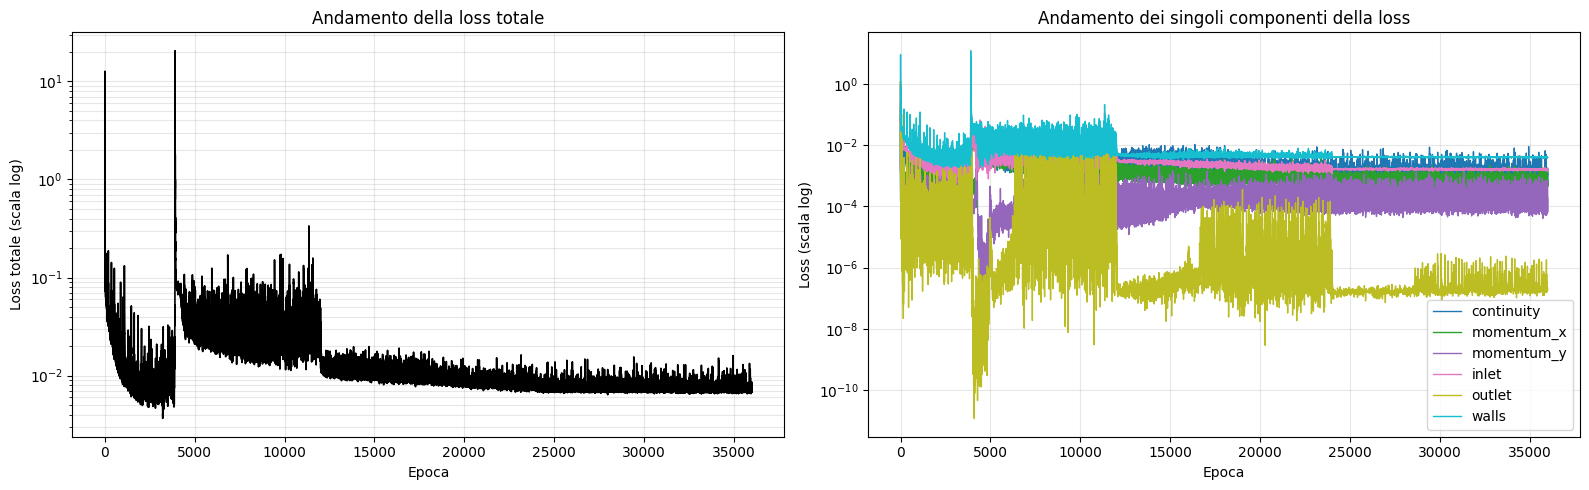

In [ ]:
# @markdown Grafico delle Loss
model.eval()

# PLOT DELLA LOSS (totale e singoli componenti)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

full_component_names = ["total", "continuity", "momentum_x", "momentum_y", "inlet", "outlet", "walls"]
history_np = history_gpu.cpu().numpy()
history = {key: history_np[:, i] for i, key in enumerate(full_component_names)}

epochs_range = np.arange(len(history["continuity"])) # Using 'continuity' as it's guaranteed to be there after the fix

axes[0].plot(epochs_range, history["total"], color="black", linewidth=1.2)
axes[0].set_yscale("log")
axes[0].set_xlabel("Epoca")
axes[0].set_ylabel("Loss totale (scala log)")
axes[0].set_title("Andamento della loss totale")
axes[0].grid(True, which="both", alpha=0.3)

component_names = ["continuity", "momentum_x", "momentum_y", "inlet", "outlet", "walls"]
colors = plt.cm.tab10(np.linspace(0, 1, len(component_names)))

for name, color in zip(component_names, colors):
    axes[1].plot(epochs_range, history[name], label=name, color=color, linewidth=1.0)

axes[1].set_yscale("log")
axes[1].set_xlabel("Epoca")
axes[1].set_ylabel("Loss (scala log)")
axes[1].set_title("Andamento dei singoli componenti della loss")
axes[1].legend()
axes[1].grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

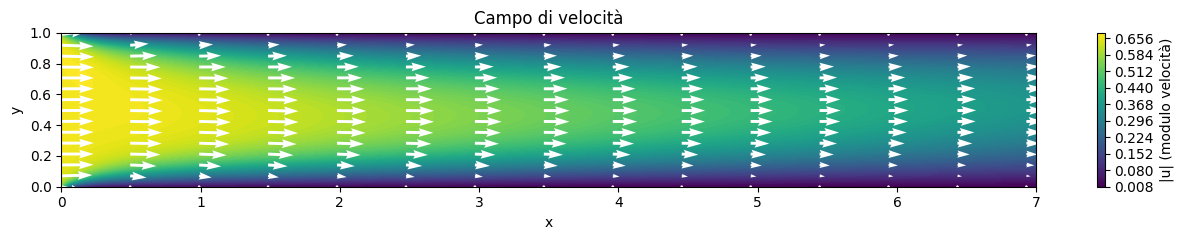

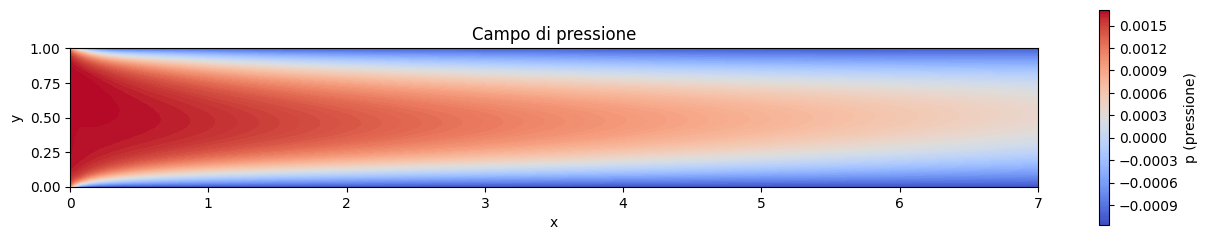

In [ ]:
#@markdown Plot di velocità e pressione

# Superficie colorata secondo il modulo + vettori sovrapposti

def evaluate_velocity_field(model, n_grid=100):
    """Valuta u, v, p su una griglia regolare (x, y) al tempo t_value."""
    x_lin = np.linspace(0, Lx, n_grid)
    y_lin = np.linspace(0, Ly, n_grid)
    X_grid, Y_grid = np.meshgrid(x_lin, y_lin)

    x_flat = X_grid.reshape(-1, 1)
    y_flat = Y_grid.reshape(-1, 1)
    # t_flat = np.full_like(x_flat)

    x_t = torch.tensor(x_flat, dtype=torch.float32).to(device)
    y_t = torch.tensor(y_flat, dtype=torch.float32).to(device)
    # t_t = torch.tensor(t_flat, dtype=torch.float32).to(device)

    with torch.no_grad():
        u, v, p = net_uvp(model, x_t, y_t#, t_t
                          )

    U = u.cpu().numpy().reshape(n_grid, n_grid)
    V = v.cpu().numpy().reshape(n_grid, n_grid)
    P = p.cpu().numpy().reshape(n_grid, n_grid)

    return X_grid, Y_grid, U, V, P


n_grid = 100
quiver_stride = 7  # sottocampiono le frecce per leggibilità

X_grid, Y_grid, U, V, P = evaluate_velocity_field(model, n_grid=n_grid)
speed = np.sqrt(U**2 + V**2)

# plot della velocità
fig_vel, ax_vel = plt.subplots(figsize=(13,2.5))

c = ax_vel.contourf(X_grid, Y_grid, speed, levels=100, cmap="viridis")

ax_vel.quiver(
        X_grid[::quiver_stride, ::quiver_stride],
        Y_grid[::quiver_stride, ::quiver_stride],
        U[::quiver_stride, ::quiver_stride],
        V[::quiver_stride, ::quiver_stride],
        color="white", scale=20, width=0.003
    )

ax_vel.set_title(f"Campo di velocità")
ax_vel.set_xlabel("x")
ax_vel.set_ylabel("y")

fig_vel.colorbar(c, ax=ax_vel, label="|u| (modulo velocità)")

plt.tight_layout()
plt.show()

# PLOT DELLA PRESSIONE

fig2, ax2 = plt.subplots(figsize=(13,2.5))

c2 = ax2.contourf(X_grid, Y_grid, P, levels=100, cmap="coolwarm")

ax2.set_title("Campo di pressione")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_aspect("equal")

fig2.colorbar(c2, ax=ax2, label="p (pressione)")

plt.tight_layout()
plt.show()

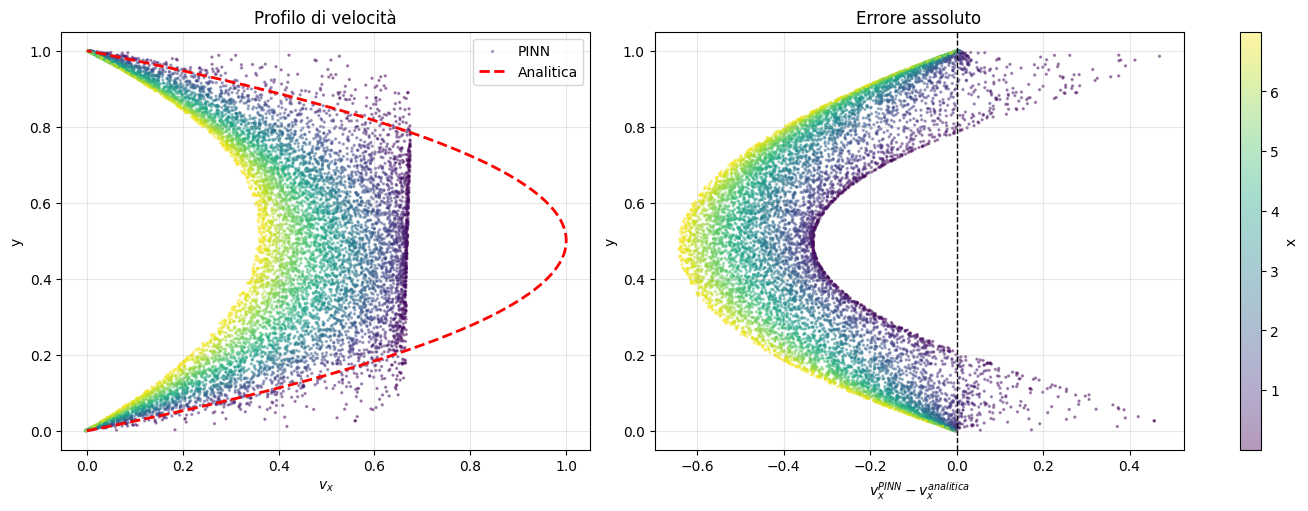

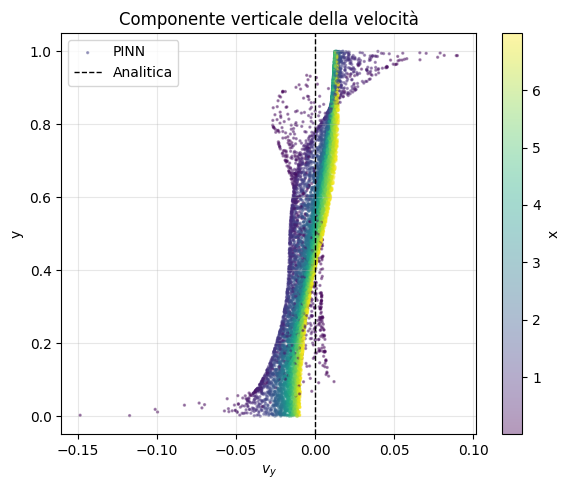

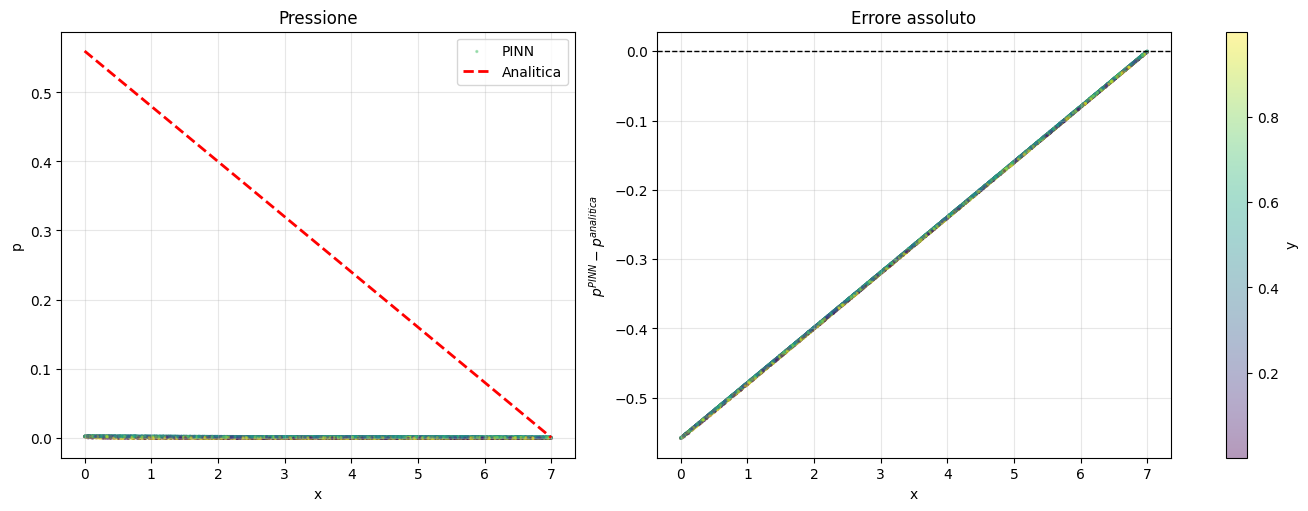

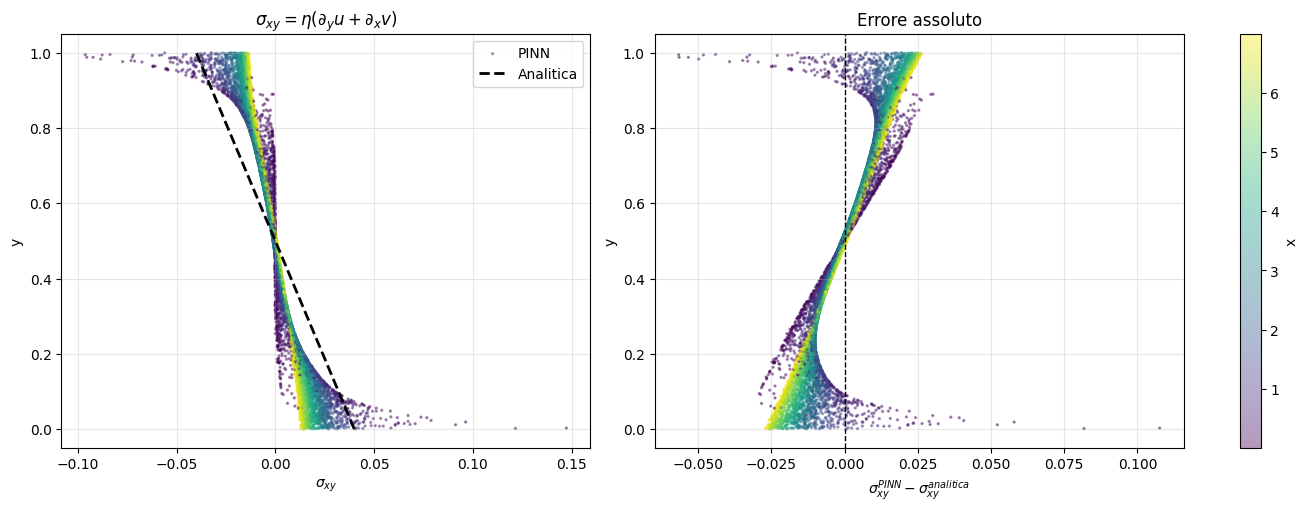

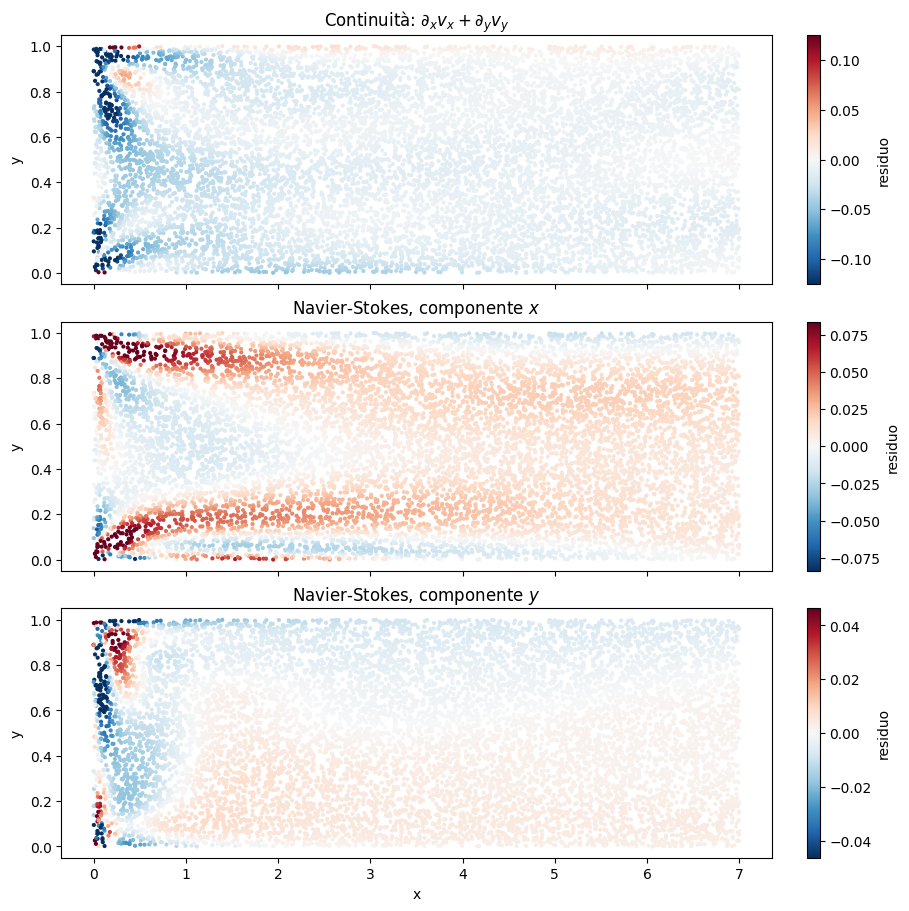

Punti di test: 10000
--------------------------------------------
Errore relativo u:        0.469621 (46.962%)  | max |errore|: 6.430e-01
Errore v (norm. su |u|):  0.019038 (1.904%)  | max |v|:      1.485e-01
Errore relativo p:        0.998140 (99.814%)  | max |errore|: 5.586e-01
Errore relativo sigma_xy: 0.512908 (51.291%)  | max |errore|: 1.076e-01
--------------------------------------------
RMS continuità:  3.028e-02   (RMS^2 = 9.17e-04)
RMS momento x:   2.734e-02   (51.26% della scala dei termini, 0.053)
RMS momento y:   1.136e-02   (21.31% della scala dei termini, 0.053)
--------------------------------------------
Peso del termine eta*dv/dx su sigma:      1.79e-02  (esatto: 0)
Peso del termine eta*du/dy su sigma:      0.613228  (esatto: 1)
Errore su sigma dal solo termine eta*du/dy: 5.11e-01


In [ ]:
# @markdown Verifica analitica della soluzione della PINN (u, v, p, $\sigma_{xy}$ e residui delle equazioni)

eta = inv_Re

to_np = lambda t: t.detach().cpu().numpy().flatten()
rms = lambda a: np.sqrt(np.mean(a**2))

# punti di test: gli stessi X_f, Y_f usati per la pressione
# (con il mini-batching non entrano mai nel training: fanno da test set indipendente)
x_p = X_f.detach()
y_p = Y_f.detach()
x_p_np = to_np(x_p)
y_p_np = to_np(y_p)

# soluzioni analitiche
# v = 0 ovunque. p: p_x = (1/Re) u_yy = -8 U / (Re Ly^2), p indipendente da y, p(Lx) = 0
def p_analytical(x):
    return 8 * U_ref / (Re * Ly**2) * (Lx - x)

def sigma_xy_analytical(y):
    # u = 4 U y (Ly - y) / Ly^2  ->  du/dy = 4 U (Ly - 2y) / Ly^2
    # con U_inlet = 1, eta = 0.01, Ly = 1 diventa 0.04 - 0.08 y
    return eta * 4 * U_ref * (Ly - 2*y) / Ly**2

def sigma_xy_pinn(model, x, y):
    # servono i gradienti, quindi niente torch.no_grad()
    x = x.clone().requires_grad_(True)
    y = y.clone().requires_grad_(True)
    u, v, _ = net_uvp(model, x, y)
    u_y = torch.autograd.grad(u, y, grad_outputs=torch.ones_like(u), create_graph=False, retain_graph=True)[0]
    v_x = torch.autograd.grad(v, x, grad_outputs=torch.ones_like(v), create_graph=False)[0]
    return eta * (u_y + v_x), u_y, v_x

u_ana_np = to_np(poiseuille_profile(y_p, U_ref, Ly))
norm_u_ana = np.linalg.norm(u_ana_np)
p_ana_np = p_analytical(x_p_np)
sig_ana = sigma_xy_analytical(y_p_np)
norm_sig_ana = np.linalg.norm(sig_ana)

# scala dei termini nel bilancio di quantità di moto (gradiente di pressione = termine viscoso)
dpdx_scale = 8 * U_inlet / (Re * Ly**2)     # = 0.08 con i parametri usati

# predizioni della rete sugli stessi punti
with torch.no_grad():
    u_pred, v_pred, p_pred = net_uvp(model, x_p, y_p)
u_pred_np, v_pred_np, p_pred_np = to_np(u_pred), to_np(v_pred), to_np(p_pred)

sig, u_y, v_x = sigma_xy_pinn(model, x_p, y_p)

# residui delle equazioni (servono copie con requires_grad)
x_r = x_p.clone().requires_grad_(True)
y_r = y_p.clone().requires_grad_(True)
cont, mom_x, mom_y = navier_stokes_residual(model, x_r, y_r, eta)

sig_np  = to_np(sig)
v_x_np  = to_np(v_x)
u_y_np  = to_np(u_y)
cont_np = to_np(cont)
mx      = to_np(mom_x)
my      = to_np(mom_y)

# errori puntuali (con segno: PINN - analitica)
err_u = u_pred_np - u_ana_np
err_p = p_pred_np - p_ana_np
err_sig = sig_np - sig_ana
# per v_y e per i residui il valore esatto è zero: l'errore coincide col valore

# errori relativi (tutti sugli stessi N punti)
rel_error_u = np.linalg.norm(err_u) / norm_u_ana
rel_error_v = np.linalg.norm(v_pred_np) / norm_u_ana     # v esatta = 0, normalizzo con |u_analitica|
rel_error_p = np.linalg.norm(err_p) / np.linalg.norm(p_ana_np)
rel_error_sig = np.linalg.norm(err_sig) / norm_sig_ana

# residui: RMS (non dipende dal numero di punti; RMS^2 è l'MSE confrontabile con la loss)
rms_cont = rms(cont_np)
rms_mx = rms(mx)
rms_my = rms(my)

# decomposizione dell'errore su sigma_xy nei due termini
vx_contrib = np.linalg.norm(eta * v_x_np) / norm_sig_ana              # peso di eta*dv/dx (esatto: 0)
uy_contrib = np.linalg.norm(eta * u_y_np) / norm_sig_ana              # peso di eta*du/dy (esatto: 1)
err_sig_da_u = np.linalg.norm(eta * u_y_np - sig_ana) / norm_sig_ana  # errore del solo termine eta*du/dy

# curva analitica per i grafici
y_line = np.linspace(0, Ly, 200)
u_line = to_np(poiseuille_profile(torch.tensor(y_line, dtype=torch.float32).to(device), U_ref, Ly))
x_line = np.array([0, Lx])

# Figura 1: v_x (colore = x) + errore
fig_vx, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
sc = axes[0].scatter(u_pred_np, y_p_np, c=x_p_np, s=2, alpha=0.4, cmap="viridis", label="PINN")
axes[0].plot(u_line, y_line, 'r--', linewidth=2, label="Analitica")
axes[1].scatter(err_u, y_p_np, c=x_p_np, s=2, alpha=0.4, cmap="viridis")
axes[1].axvline(0, color='k', linestyle='--', linewidth=1)
fig_vx.colorbar(sc, ax=axes, label="x")
axes[0].set_xlabel("$v_x$"); axes[0].set_ylabel("y")
axes[0].set_title("Profilo di velocità")
axes[1].set_xlabel(r"$v_x^{PINN}-v_x^{analitica}$"); axes[1].set_ylabel("y")
axes[1].set_title("Errore assoluto")
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].legend()
plt.savefig("v_x.pdf"); plt.show()

# Figura 2: v_y (colore = x)  -- un solo pannello: il grafico della grandezza è già l'errore assoluto
fig_vy, ax_vy = plt.subplots(figsize=(6, 5))
sc = ax_vy.scatter(v_pred_np, y_p_np, c=x_p_np, s=2, alpha=0.4, cmap="viridis", label="PINN")
ax_vy.axvline(0, color="k", linestyle="--", linewidth=1, label="Analitica")
fig_vy.colorbar(sc, ax=ax_vy, label="x")
ax_vy.set_xlabel("$v_y$"); ax_vy.set_ylabel("y")
ax_vy.set_title("Componente verticale della velocità"); ax_vy.grid(alpha=0.3); ax_vy.legend()
fig_vy.tight_layout(); plt.savefig("v_y.pdf"); plt.show()

# Figura 3: pressione (colore = y) + errore
fig_p, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
sc = axes[0].scatter(x_p_np, p_pred_np, c=y_p_np, s=2, alpha=0.4, cmap="viridis", label="PINN")
axes[0].plot(x_line, p_analytical(x_line), 'r--', linewidth=2, label="Analitica")
axes[1].scatter(x_p_np, err_p, c=y_p_np, s=2, alpha=0.4, cmap="viridis")
axes[1].axhline(0, color='k', linestyle='--', linewidth=1)
fig_p.colorbar(sc, ax=axes, label="y")
axes[0].set_xlabel("x"); axes[0].set_ylabel("p")
axes[0].set_title("Pressione")
axes[1].set_xlabel("x"); axes[1].set_ylabel(r"$p^{PINN}-p^{analitica}$")
axes[1].set_title("Errore assoluto")
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].legend()
plt.savefig("pressione.pdf"); plt.show()

# Figura 4: sigma_xy (colore = x) + errore
fig_s, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
sc = axes[0].scatter(sig_np, y_p_np, c=x_p_np, s=2, alpha=0.4, cmap="viridis", label="PINN")
axes[0].plot(sigma_xy_analytical(y_line), y_line, '--', color='k', linewidth=2, label="Analitica")
axes[1].scatter(err_sig, y_p_np, c=x_p_np, s=2, alpha=0.4, cmap="viridis")
axes[1].axvline(0, color='k', linestyle='--', linewidth=1)
fig_s.colorbar(sc, ax=axes, label="x")
axes[0].set_xlabel(r"$\sigma_{xy}$"); axes[0].set_ylabel("y")
axes[0].set_title(r"$\sigma_{xy}=\eta(\partial_y u+\partial_x v)$")
axes[1].set_xlabel(r"$\sigma_{xy}^{PINN}-\sigma_{xy}^{analitica}$"); axes[1].set_ylabel("y")
axes[1].set_title("Errore assoluto")
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].legend()
plt.savefig("sigma.pdf"); plt.show()

# Figura 5: residui delle equazioni (mappe nel piano x-y, scala divergente centrata in 0)
fig_r, axes = plt.subplots(3, 1, figsize=(9, 9), layout="constrained", sharex=True)
for ax, r, titolo in zip(axes, [cont_np, mx, my],
                         [r"Continuità: $\partial_x v_x+\partial_y v_y$",
                          "Navier-Stokes, componente $x$",
                          "Navier-Stokes, componente $y$"]):
    lim = np.percentile(np.abs(r), 99)       # evita che pochi outlier schiaccino la scala
    sc = ax.scatter(x_p_np, y_p_np, c=r, s=4, cmap="RdBu_r", vmin=-lim, vmax=lim)
    fig_r.colorbar(sc, ax=ax, label="residuo")
    ax.set_ylabel("y"); ax.set_title(titolo)
axes[-1].set_xlabel("x")
plt.savefig("residui.pdf"); plt.show()

# riepilogo
print(f"Punti di test: {x_p_np.size}")
print("--------------------------------------------")
print(f"Errore relativo u:        {rel_error_u:.6f} ({rel_error_u*100:.3f}%)  | max |errore|: {np.abs(err_u).max():.3e}")
print(f"Errore v (norm. su |u|):  {rel_error_v:.6f} ({rel_error_v*100:.3f}%)  | max |v|:      {np.abs(v_pred_np).max():.3e}")
print(f"Errore relativo p:        {rel_error_p:.6f} ({rel_error_p*100:.3f}%)  | max |errore|: {np.abs(err_p).max():.3e}")
print(f"Errore relativo sigma_xy: {rel_error_sig:.6f} ({rel_error_sig*100:.3f}%)  | max |errore|: {np.abs(err_sig).max():.3e}")
print("--------------------------------------------")
print(f"RMS continuità:  {rms_cont:.3e}   (RMS^2 = {rms_cont**2:.2e})")
print(f"RMS momento x:   {rms_mx:.3e}   ({rms_mx/dpdx_scale*100:.2f}% della scala dei termini, {dpdx_scale:.3f})")
print(f"RMS momento y:   {rms_my:.3e}   ({rms_my/dpdx_scale*100:.2f}% della scala dei termini, {dpdx_scale:.3f})")
print("--------------------------------------------")
print(f"Peso del termine eta*dv/dx su sigma:      {vx_contrib:.2e}  (esatto: 0)")
print(f"Peso del termine eta*du/dy su sigma:      {uy_contrib:.6f}  (esatto: 1)")
print(f"Errore su sigma dal solo termine eta*du/dy: {err_sig_da_u:.2e}")

x=0.00 | errore rel. u: 0.383796 (38.380%) | errore v (norm. su |u|): 0.025253 (2.525%)
x=1.00 | errore rel. u: 0.290187 (29.019%) | errore v (norm. su |u|): 0.027243 (2.724%)
x=2.00 | errore rel. u: 0.367716 (36.772%) | errore v (norm. su |u|): 0.020073 (2.007%)
x=3.00 | errore rel. u: 0.433653 (43.365%) | errore v (norm. su |u|): 0.016293 (1.629%)
x=4.00 | errore rel. u: 0.491721 (49.172%) | errore v (norm. su |u|): 0.014186 (1.419%)
x=5.00 | errore rel. u: 0.544869 (54.487%) | errore v (norm. su |u|): 0.013012 (1.301%)
x=6.00 | errore rel. u: 0.594515 (59.452%) | errore v (norm. su |u|): 0.012931 (1.293%)
x=7.00 | errore rel. u: 0.642947 (64.295%) | errore v (norm. su |u|): 0.014061 (1.406%)


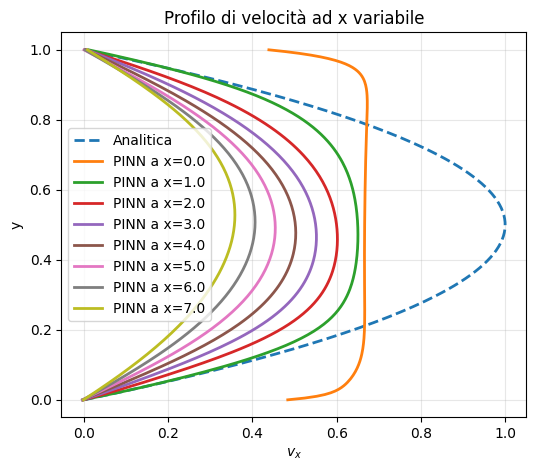

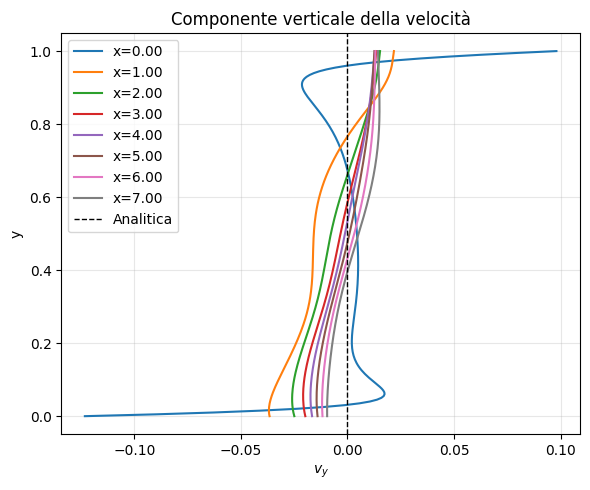

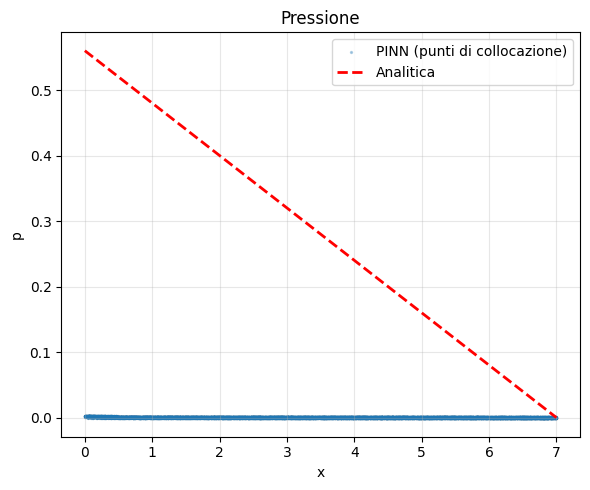

    x |   err. rel. sigma_xy |   max |errore| |  sigma_xy(y=0) |  sigma_xy(y=Ly) |  |eta*v_x|/|sigma|
 0.00 |             0.935655 |      4.768e-02 |        0.07098 |        -0.07434 |           3.34e-01
 1.00 |             0.391342 |      1.600e-02 |        0.04267 |        -0.03870 |           5.35e-03
 2.00 |             0.171929 |      4.786e-03 |        0.03097 |        -0.02650 |           3.61e-03
 3.00 |             0.178614 |      5.957e-03 |        0.02480 |        -0.02071 |           1.53e-03
 4.00 |             0.246182 |      9.169e-03 |        0.02081 |        -0.01750 |           1.18e-03
 5.00 |             0.317874 |      1.095e-02 |        0.01776 |        -0.01572 |           1.30e-03
 6.00 |             0.394124 |      1.217e-02 |        0.01514 |        -0.01449 |           1.48e-03
 7.00 |             0.474176 |      1.388e-02 |        0.01279 |        -0.01332 |           1.59e-03


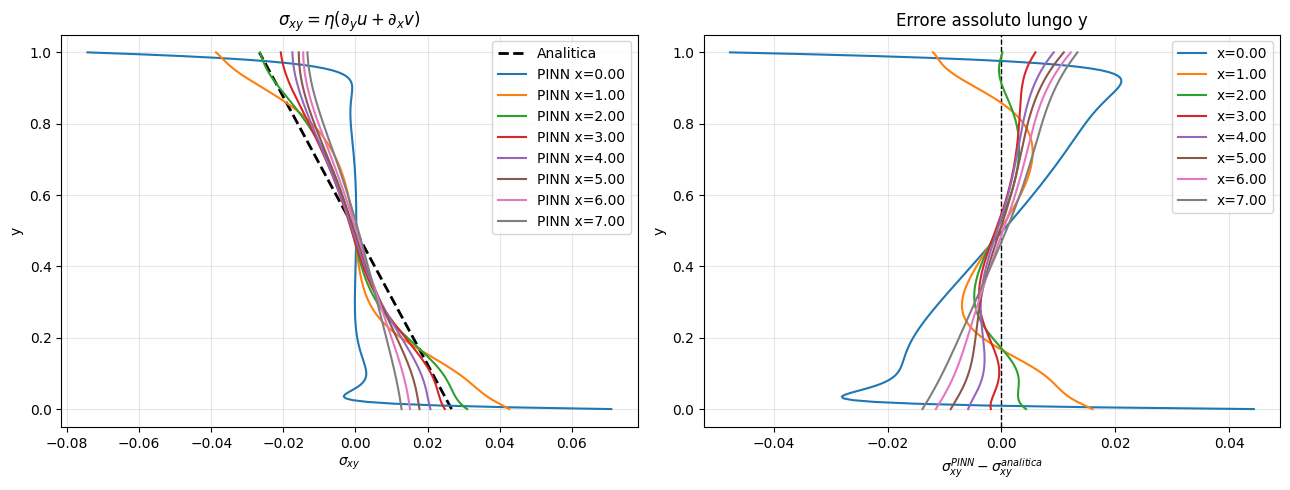

--------------------------------------------
Media errori relativi u (su 8 sezioni): 0.468675 (46.868%)
Media errori v (norm. su |u|):                  0.017881 (1.788%)
Errore relativo p (su 10000 punti):          0.998140 (99.814%)
Media errori relativi sigma_xy (su 8 sezioni): 0.388737 (38.874%)
Valori attesi a parete: sigma_xy(0) = 0.02667, sigma_xy(Ly) = -0.02667


In [ ]:
# @markdown Verifica analitica della soluzione della PINN (u, v, p e $\sigma_{xy}$)

locs = 7
eta = inv_Re
n_sections = locs + 1   # il ciclo va da i=0 a i=locs inclusi, quindi le sezioni sono locs+1

# soluzioni analitiche
y_test = np.linspace(0, Ly, 200).reshape(-1, 1)
u_analytical = poiseuille_profile(torch.tensor(y_test, dtype=torch.float32).to(device), U_ref, Ly)
u_analytical_np = u_analytical.cpu().numpy().flatten()   # (200,) come u_pred_np, niente broadcasting
norm_u_ana = np.linalg.norm(u_analytical_np)

# v = 0 ovunque. p: p_x = (1/Re) u_yy = -8 U / (Re Ly^2), p indipendente da y, p(Lx) = 0
def p_analytical(x):
    return 8 * U_ref / (Re * Ly**2) * (Lx - x)

def sigma_xy_analytical(y):
    # u = 4 U y (Ly - y) / Ly^2  ->  du/dy = 4 U (Ly - 2y) / Ly^2
    # con U_inlet = 1, eta = 0.01, Ly = 1 diventa 0.04 - 0.08 y
    return eta * 4 * U_inlet * (Ly - 2*y) / Ly**2

def sigma_xy_pinn(model, x, y):
    # servono i gradienti, quindi niente torch.no_grad()
    x = x.clone().requires_grad_(True)
    y = y.clone().requires_grad_(True)
    u, v, _ = net_uvp(model, x, y)
    u_y = torch.autograd.grad(u, y, grad_outputs=torch.ones_like(u), create_graph=False, retain_graph=True)[0]
    v_x = torch.autograd.grad(v, x, grad_outputs=torch.ones_like(v), create_graph=False)[0]
    return eta * (u_y + v_x), u_y, v_x

# raccolta di u e v e plot di u alle sezioni
plt.figure(figsize=(6,5))
plt.xlabel("$v_x$")
plt.ylabel("y")
plt.title("Profilo di velocità ad x variabile")
plt.grid(alpha=0.3)

plt.plot(u_analytical_np, y_test, '--', label="Analitica", linewidth=2)

m_u = 0
m_v = 0
v_profiles = []
for i in range(n_sections):
  x_fixed = np.full_like(y_test, i*Lx/locs)   # sezione a x = i*Lx/locs (i=0 è l'inlet, dove u è imposta come BC)

  x_t = torch.tensor(x_fixed, dtype=torch.float32).to(device)
  y_t = torch.tensor(y_test, dtype=torch.float32).to(device)

  with torch.no_grad():
    u_pred, v_pred, p_pred = net_uvp(model, x_t, y_t)

  u_pred_np = u_pred.cpu().numpy().flatten()
  v_pred_np = v_pred.cpu().numpy().flatten()
  v_profiles.append((i*Lx/locs, v_pred_np))

  plt.plot(u_pred_np, y_test, label=f"PINN a x={i*Lx/locs}", linewidth=2)

  rel_error_u = np.linalg.norm(u_pred_np - u_analytical_np) / norm_u_ana
  rel_error_v = np.linalg.norm(v_pred_np) / norm_u_ana   # v esatta = 0, normalizzo con |u_analitica|
  m_u += rel_error_u
  m_v += rel_error_v
  print(f"x={i*Lx/locs:.2f} | errore rel. u: {rel_error_u:.6f} ({rel_error_u*100:.3f}%) | "
        f"errore v (norm. su |u|): {rel_error_v:.6f} ({rel_error_v*100:.3f}%)")
plt.legend()
plt.show()

# valutazione della pressione
# Con il mini-batching X_f, Y_f non entrano mai nel training: fanno da test set indipendente.
# ATTENZIONE: con collocation point fissati e usati come punti di training, l'errore sarebbe ottimistico.
x_p = X_f.detach()
y_p = Y_f.detach()
with torch.no_grad():
  _, _, p_pred_f = net_uvp(model, x_p, y_p)

p_pred_np = p_pred_f.cpu().numpy().flatten()
x_p_np = x_p.cpu().numpy().flatten()
p_ana_np = p_analytical(x_p_np)
rel_error_p = np.linalg.norm(p_pred_np - p_ana_np) / np.linalg.norm(p_ana_np)


# Figura 1: componente verticale v
fig_v, ax_v = plt.subplots(figsize=(6, 5))
for x_loc, v_np in v_profiles:
  ax_v.plot(v_np, y_test, label=f"x={x_loc:.2f}", linewidth=1.5)
ax_v.axvline(0, color="k", linestyle="--", linewidth=1, label="Analitica")
ax_v.set_xlabel("$v_y$")
ax_v.set_ylabel("y")
ax_v.set_title("Componente verticale della velocità")
ax_v.grid(alpha=0.3)
ax_v.legend()
fig_v.tight_layout()
plt.show()

# Figura 2: pressione
fig_p, ax_p = plt.subplots(figsize=(6, 5))
ax_p.scatter(x_p_np, p_pred_np, s=2, alpha=0.3, label="PINN (punti di collocazione)")
x_line = np.array([0, Lx])
ax_p.plot(x_line, p_analytical(x_line), 'r--', linewidth=2, label="Analitica")
ax_p.set_xlabel("x")
ax_p.set_ylabel("p")
ax_p.set_title("Pressione")
ax_p.grid(alpha=0.3)
ax_p.legend()
fig_p.tight_layout()
plt.show()

# Figure 3: sigma_xy

y_flat = y_test.flatten()
sig_ana = sigma_xy_analytical(y_flat)
norm_sig_ana = np.linalg.norm(sig_ana)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(sig_ana, y_flat, '--', color='k', linewidth=2, label="Analitica")
axes[1].axvline(0, color='k', linestyle='--', linewidth=1)

m_sig = 0
sigma_profiles = []
print(f"{'x':>5} | {'err. rel. sigma_xy':>20} | {'max |errore|':>14} | {'sigma_xy(y=0)':>14} | {'sigma_xy(y=Ly)':>15} | {'|eta*v_x|/|sigma|':>18}")
for i in range(n_sections):
    x_loc = i * Lx / locs
    x_t = torch.tensor(np.full_like(y_test, x_loc), dtype=torch.float32).to(device)
    y_t = torch.tensor(y_test, dtype=torch.float32).to(device)

    sig, u_y, v_x = sigma_xy_pinn(model, x_t, y_t)
    sig_np = sig.detach().cpu().numpy().flatten()
    v_x_np = v_x.detach().cpu().numpy().flatten()
    sigma_profiles.append((x_loc, sig_np))

    err = sig_np - sig_ana
    rel_err = np.linalg.norm(err) / norm_sig_ana
    m_sig += rel_err
    vx_contrib = np.linalg.norm(eta * v_x_np) / norm_sig_ana   # quanto pesa il termine dv/dx

    print(f"{x_loc:5.2f} | {rel_err:20.6f} | {np.abs(err).max():14.3e} | {sig_np[0]:14.5f} | {sig_np[-1]:15.5f} | {vx_contrib:18.2e}")

    axes[0].plot(sig_np, y_flat, label=f"PINN x={x_loc:.2f}", linewidth=1.5)
    axes[1].plot(err, y_flat, label=f"x={x_loc:.2f}", linewidth=1.5)

axes[0].set_xlabel(r"$\sigma_{xy}$"); axes[0].set_ylabel("y")
axes[0].set_title(r"$\sigma_{xy}=\eta(\partial_y u+\partial_x v)$")
axes[1].set_xlabel(r"$\sigma_{xy}^{PINN}-\sigma_{xy}^{analitica}$"); axes[1].set_ylabel("y")
axes[1].set_title("Errore assoluto lungo y")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

# riepilogo
print("--------------------------------------------")
print(f"Media errori relativi u (su {n_sections} sezioni): {m_u/n_sections:.6f} ({m_u*100/n_sections:.3f}%)")
print(f"Media errori v (norm. su |u|):                  {m_v/n_sections:.6f} ({m_v*100/n_sections:.3f}%)")
print(f"Errore relativo p (su {x_p_np.size} punti):          {rel_error_p:.6f} ({rel_error_p*100:.3f}%)")
print(f"Media errori relativi sigma_xy (su {n_sections} sezioni): {m_sig/n_sections:.6f} ({m_sig*100/n_sections:.3f}%)")
print(f"Valori attesi a parete: sigma_xy(0) = {sigma_xy_analytical(0.0):.5f}, sigma_xy(Ly) = {sigma_xy_analytical(Ly):.5f}")

Portata media:                 0.378046
Deviazione standard di Q:      1.016712e-01
Portata minima:                0.238031 (x = 7.000)
Portata massima:               0.656123 (x = 0.000)
Oscillazione relativa max-min: 110.5930%


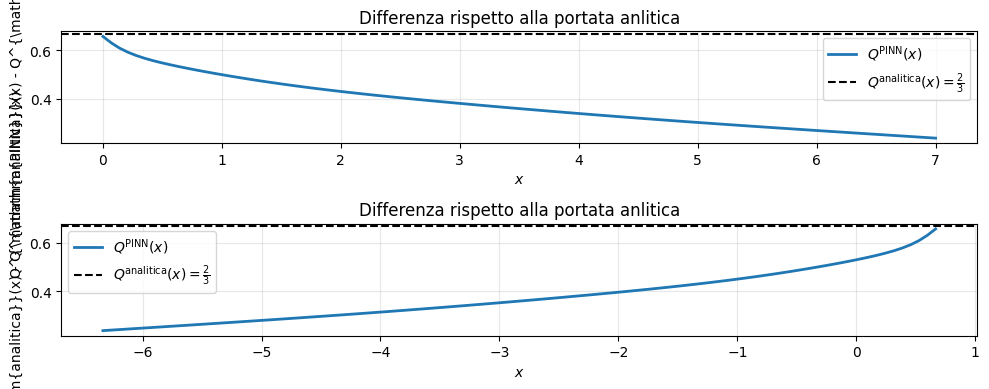

In [ ]:

# @markdown Portata volumetrica Q(x) attraverso sezioni del canale

# Griglie regolari: nessun punto casuale di collocazione
n_sections = 101  # numero di sezioni lungo x
n_y = 501         # punti di integrazione lungo y

x_sections = np.linspace(0, Lx, n_sections)
y_grid = np.linspace(0, Ly, n_y)

# Griglia cartesiana (x,y), con n_y punti per ciascuna sezione
X_sec, Y_sec = np.meshgrid(x_sections, y_grid, indexing="ij")

x_t = torch.tensor(
    X_sec.reshape(-1, 1), dtype=torch.float32, device=device
)
y_t = torch.tensor(
    Y_sec.reshape(-1, 1), dtype=torch.float32, device=device
)

# Valutazione della PINN
model.eval()
with torch.no_grad():
    u_pred, v_pred, p_pred = net_uvp(model, x_t, y_t)

# La componente longitudinale u coincide con vx
u_grid = u_pred.detach().cpu().numpy().reshape(n_sections, n_y)

# Integrazione numerica di u(x,y) rispetto a y
Q = np.trapezoid(u_grid, x=y_grid, axis=1)

# Riepilogo numerico
Q_mean = np.mean(Q)
Q_std = np.std(Q)
Q_rel_variation = (Q.max() - Q.min()) / abs(Q_mean) if Q_mean != 0 else np.nan

print(f"Portata media:                 {Q_mean:.6f}")
print(f"Deviazione standard di Q:      {Q_std:.6e}")
print(f"Portata minima:                {Q.min():.6f} (x = {x_sections[Q.argmin()]:.3f})")
print(f"Portata massima:               {Q.max():.6f} (x = {x_sections[Q.argmax()]:.3f})")
print(f"Oscillazione relativa max-min: {100*Q_rel_variation:.4f}%")

# Grafico della portata lungo il canale
fig, ax = plt.subplots(2,1,figsize=(10, 4))

ax[0].plot(x_sections, Q, linewidth=2, label=r"$Q^{\mathrm{PINN}}(x)$")
ax[0].axhline(2/3, color="black", linestyle="--",
              label=r"$Q^{\mathrm{analitica}}(x)=\frac{2}{3}$")

ax[0].set_xlabel("$x$")
ax[0].set_ylabel(r"Q^{\mathrm{analitica}}(x) - Q^{\mathrm{PINN}}(x)")
ax[0].set_title("Differenza rispetto alla portata anlitica")
ax[0].grid(alpha=0.3)
ax[0].legend()

ax[1].plot(2/3-x_sections, Q, linewidth=2, label=r"$Q^{\mathrm{PINN}}(x)$")
ax[1].axhline(2/3, color="black", linestyle="--",
              label=r"$Q^{\mathrm{analitica}}(x)=\frac{2}{3}$")

ax[1].set_xlabel("$x$")
ax[1].set_ylabel(r"Q^{\mathrm{analitica}}(x) - Q^{\mathrm{PINN}}(x)")
ax[1].set_title("Differenza rispetto alla portata anlitica")
ax[1].grid(alpha=0.3)
ax[1].legend()

fig.tight_layout()
plt.show()
